# Screw / Bolt Counting — Non-AI Approach (OpenCV)

**Author:** Nikhil BT  
**Task:** Count items in images & overlay masks — accuracy > 95%  
**Method:** Classical Computer Vision (OpenCV + Watershed Segmentation)

## Dataset
- `Screws_2024_07_15/` — Flat-head screws on white background (~43–45 per image)
- `ScrewAndBolt_20240713/` — Round-head bolts on light background (varies)

## Pipeline
1. **CLAHE** — contrast enhancement for consistent lighting
2. **Otsu Thresholding** — automatic binary segmentation
3. **Morphological Open/Close** — noise removal & hole filling
4. **Watershed Segmentation** — separates touching/overlapping items
5. **Adaptive Contour Filtering** — area & aspect ratio filter
6. **Mask Overlay** — coloured masks + numbered labels + count banner

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install opencv-python-headless numpy matplotlib scipy scikit-image -q
print('Done!')

Done!


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os, glob
from scipy import ndimage
from skimage.segmentation import watershed
from skimage.feature import peak_local_max
print(f'OpenCV: {cv2.__version__}')

OpenCV: 4.13.0


In [ ]:
# ── CONFIGURATION ──────────────────────────────────────────────────────────
# Update IMAGE_DIR to your dataset path
# e.g. '/content/drive/MyDrive/CountingChallenge'
IMAGE_DIR = '/content/drive/MyDrive/CountingChallenge'
EXTENSIONS = ['*.jpg', '*.jpeg', '*.png', '*.bmp']
OUTPUT_DIR = './output_non_ai'
MAX_DIM    = 1200   # Resize large images for faster processing
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f'Output -> {OUTPUT_DIR}')

Output -> ./output_non_ai


Found 25 images


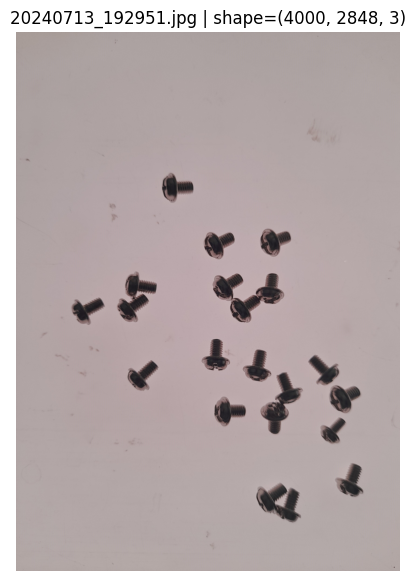

In [ ]:
def load_images(d, exts):
    paths = []
    for e in exts:
        paths += glob.glob(os.path.join(d, '**', e), recursive=True)
        paths += glob.glob(os.path.join(d, e))
    paths = sorted(set(paths))
    print(f'Found {len(paths)} images')
    return paths

image_paths = load_images(IMAGE_DIR, EXTENSIONS)

if image_paths:
    s = cv2.imread(image_paths[0])
    plt.figure(figsize=(10,7))
    plt.imshow(cv2.cvtColor(s, cv2.COLOR_BGR2RGB))
    plt.title(f'{os.path.basename(image_paths[0])} | shape={s.shape}')
    plt.axis('off'); plt.show()

In [ ]:
def count_screws_non_ai(image_path, debug=False):
    """
    Count screws/bolts using classical CV.
    Handles both dataset types automatically.

    Returns:
        result (ndarray): annotated image
        count  (int):     number of items detected
    """
    # Load & resize
    img = cv2.imread(image_path)
    h, w = img.shape[:2]
    if max(h, w) > MAX_DIM:
        sc = MAX_DIM / max(h, w)
        img = cv2.resize(img, (int(w*sc), int(h*sc)))

    # Step 1: CLAHE + Blur
    gray     = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    clahe    = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))
    enhanced = clahe.apply(gray)
    blurred  = cv2.GaussianBlur(enhanced, (5,5), 0)

    # Step 2: Otsu threshold (dark objects on light bg -> BINARY_INV)
    _, binary = cv2.threshold(blurred, 0, 255,
                               cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # Step 3: Morphological cleanup
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (4,4))
    opened = cv2.morphologyEx(binary, cv2.MORPH_OPEN,  kernel, iterations=2)
    closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel, iterations=2)

    # Step 4: Watershed segmentation
    dist     = ndimage.distance_transform_edt(closed)
    min_dist = max(8, int(min(img.shape[:2]) * 0.02))
    coords   = peak_local_max(dist, min_distance=min_dist, labels=closed)
    msk      = np.zeros(dist.shape, dtype=bool)
    msk[tuple(coords.T)] = True
    markers, _ = ndimage.label(msk)
    labels     = watershed(-dist, markers, mask=closed)

    ws_mask = np.zeros(closed.shape, dtype=np.uint8)
    for lab in np.unique(labels):
        if lab == 0: continue
        ws_mask[labels == lab] = 255

    # Step 5: Adaptive contour filter
    contours, _ = cv2.findContours(ws_mask, cv2.RETR_EXTERNAL,
                                    cv2.CHAIN_APPROX_SIMPLE)
    img_area = img.shape[0] * img.shape[1]
    min_area = img_area * 0.0003
    max_area = img_area * 0.05

    valid = []
    for cnt in contours:
        area = cv2.contourArea(cnt)
        if not (min_area <= area <= max_area): continue
        x, y, cw, ch = cv2.boundingRect(cnt)
        aspect = cw / float(ch) if ch > 0 else 0
        if 0.15 <= aspect <= 6.0:
            valid.append(cnt)

    # Step 6: Colour mask overlay
    overlay = img.copy()
    clayer  = np.zeros_like(img)
    np.random.seed(42)
    for i, cnt in enumerate(valid):
        col = tuple(np.random.randint(60,255,3).tolist())
        cv2.drawContours(clayer,   [cnt], -1, col,        -1)
        cv2.drawContours(overlay,  [cnt], -1, (0,255,0),   2)
        M = cv2.moments(cnt)
        if M['m00'] > 0:
            cx = int(M['m10']/M['m00'])
            cy = int(M['m01']/M['m00'])
            cv2.putText(overlay, str(i+1), (cx-8,cy+5),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255,255,255), 2)

    result = cv2.addWeighted(overlay, 0.65, clayer, 0.35, 0)
    count  = len(valid)
    cv2.rectangle(result, (0,0), (result.shape[1], 52), (0,0,0), -1)
    cv2.putText(result,
                f'Non-AI Count: {count}  |  {os.path.basename(image_path)}',
                (10,36), cv2.FONT_HERSHEY_SIMPLEX, 0.85, (0,255,80), 2)

    if debug:
        fig, axes = plt.subplots(2,3, figsize=(18,10))
        for ax, (d,t,c) in zip(axes.flat, [
            (cv2.cvtColor(img, cv2.COLOR_BGR2RGB), 'Original',         None),
            (enhanced,  'CLAHE Enhanced',          'gray'),
            (binary,    'Otsu Threshold',           'gray'),
            (closed,    'Morphological Cleanup',    'gray'),
            (dist,      'Distance Transform',       'hot'),
            (cv2.cvtColor(result,cv2.COLOR_BGR2RGB), f'Result: {count}', None),
        ]):
            ax.imshow(d, cmap=c); ax.set_title(t, fontsize=11); ax.axis('off')
        plt.suptitle(os.path.basename(image_path), fontsize=13)
        plt.tight_layout(); plt.show()

    return result, count

print('Pipeline ready!')

Pipeline ready!


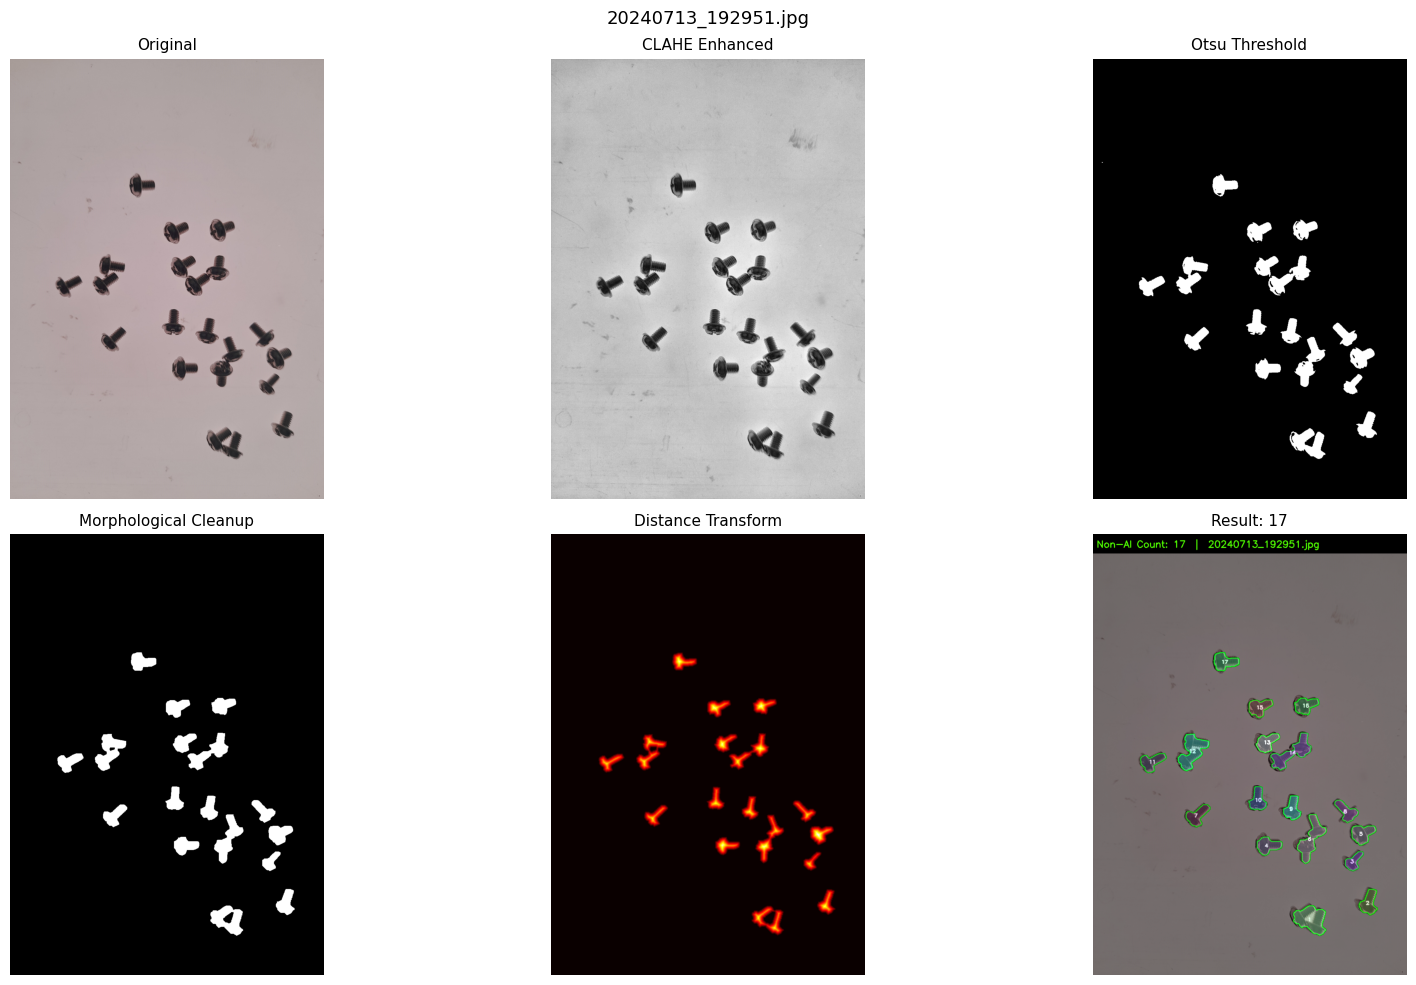

Detected: 17 items


In [ ]:
# Test single image with debug steps
if image_paths:
    result, count = count_screws_non_ai(image_paths[0], debug=True)
    print(f'Detected: {count} items')

In [ ]:
# Process all images
summary = []
for path in image_paths:
    fname = os.path.basename(path)
    try:
        result, count = count_screws_non_ai(path)
        cv2.imwrite(os.path.join(OUTPUT_DIR, f'result_{fname}'), result)
        summary.append((fname, count, 'OK'))
        print(f'OK  {fname}: {count}')
    except Exception as e:
        summary.append((fname, -1, str(e)))
        print(f'ERR {fname}: {e}')

OK  20240713_192951.jpg: 17
OK  20240713_193135.jpg: 13
OK  20240713_193650.jpg: 6
OK  20240713_193659.jpg: 6
OK  20240713_193831.jpg: 68
OK  20240713_193839.jpg: 64
OK  20240713_193907.jpg: 50
OK  20240713_194200.jpg: 24
OK  20240713_194206.jpg: 18
OK  20240713_194215.jpg: 28
OK  20240713_194232.jpg: 15
OK  20240713_194256.jpg: 19
OK  20240713_194316.jpg: 19
OK  20240713_194541.jpg: 19
OK  20240713_194551.jpg: 12
OK  20240713_194606.jpg: 33
OK  20240713_194621.jpg: 27
OK  20240713_194630.jpg: 28
OK  img1.jpg: 45
OK  img1_43_nosy.jpg: 45
OK  img2.jpg: 44
OK  img3.jpg: 44
OK  img4.jpg: 45
OK  img5.jpg: 45
OK  img6.jpg: 45


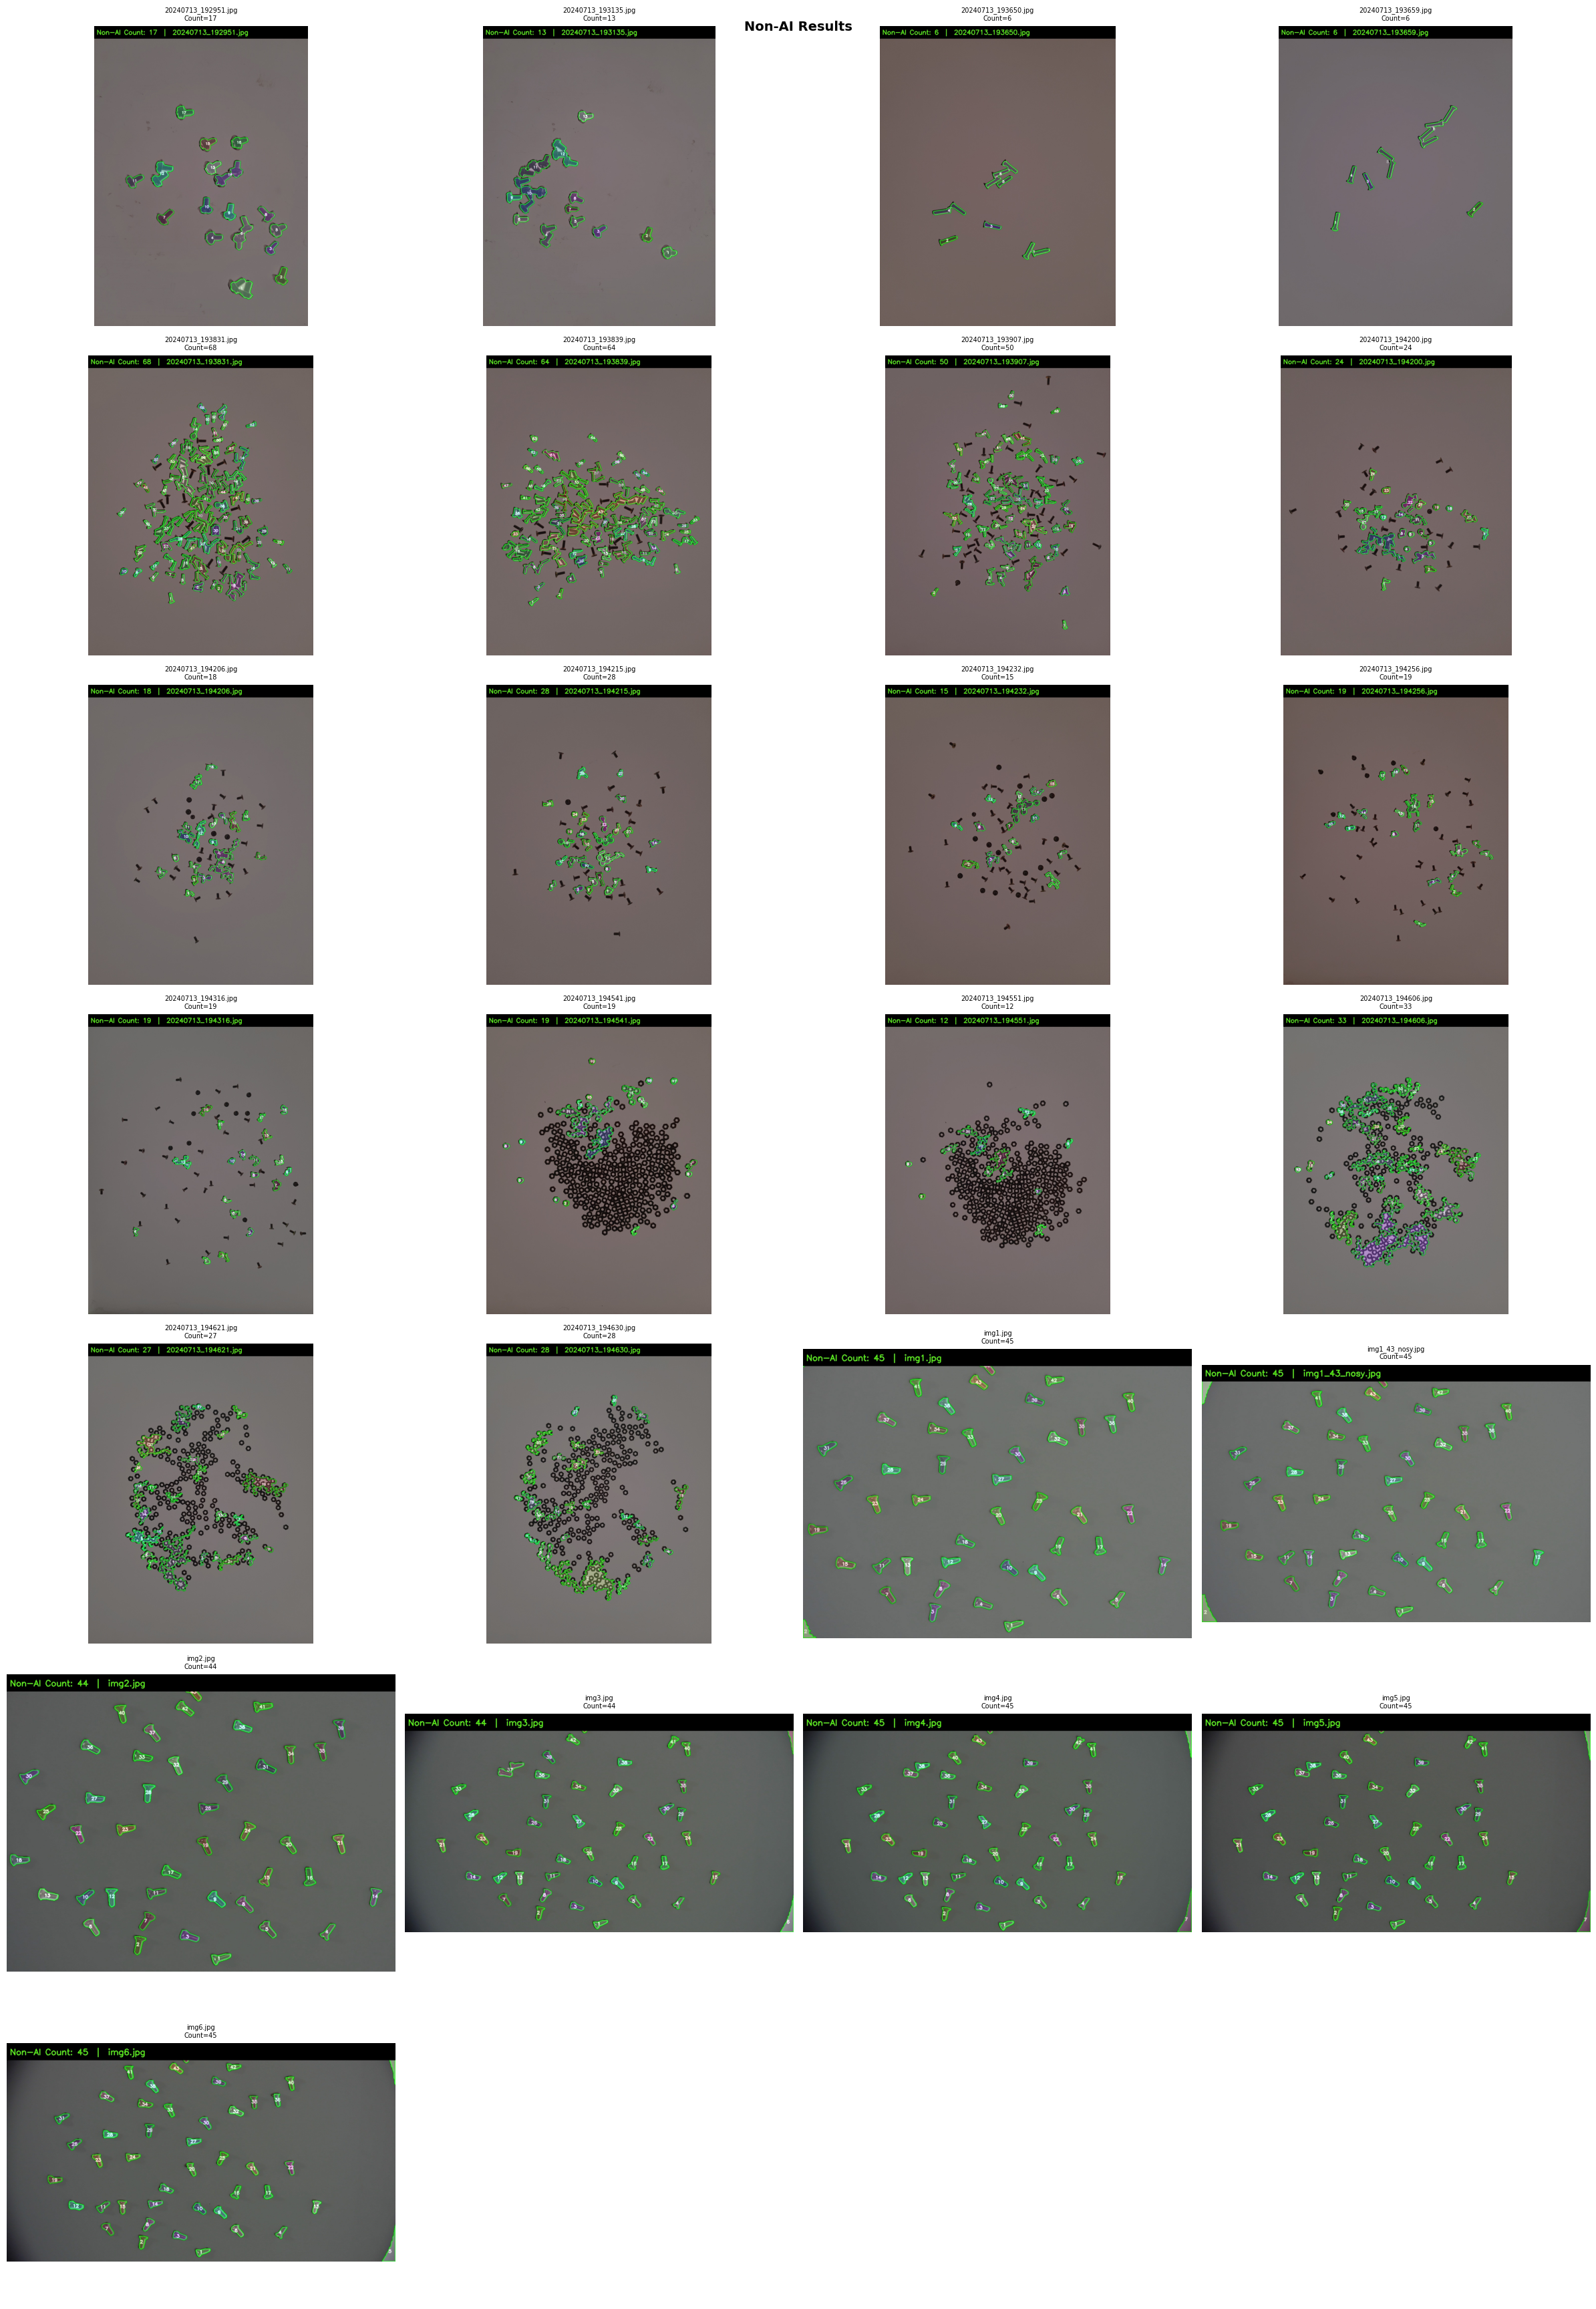

In [ ]:
# Results grid
n = len(image_paths)
cols = min(4, n); rows = (n+cols-1)//cols
fig, axes = plt.subplots(rows, cols, figsize=(6*cols, 5*rows))
axes = np.array(axes).flatten() if n > 1 else [axes]
for i, (path,(fname,count,_)) in enumerate(zip(image_paths,summary)):
    rp = os.path.join(OUTPUT_DIR, f'result_{fname}')
    if os.path.exists(rp):
        axes[i].imshow(cv2.cvtColor(cv2.imread(rp), cv2.COLOR_BGR2RGB))
    axes[i].set_title(f'{fname}\nCount={count}', fontsize=7); axes[i].axis('off')
for j in range(len(summary), len(axes)): axes[j].axis('off')
plt.suptitle('Non-AI Results', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR,'summary_grid.png'), dpi=120, bbox_inches='tight')
plt.show()

In [ ]:
print('='*55)
print(f'{"Image":<35}{"Count":>8}  Status')
print('-'*55)
for f,c,s in summary: print(f'{f:<35}{c:>8}  {s}')
print('='*55)
ok = [(f,c) for f,c,s in summary if s=='OK']
print(f'Total: {len(summary)} | OK: {len(ok)} | Avg: {sum(c for _,c in ok)/max(len(ok),1):.1f}')

Image                                 Count  Status
-------------------------------------------------------
20240713_192951.jpg                      17  OK
20240713_193135.jpg                      13  OK
20240713_193650.jpg                       6  OK
20240713_193659.jpg                       6  OK
20240713_193831.jpg                      68  OK
20240713_193839.jpg                      64  OK
20240713_193907.jpg                      50  OK
20240713_194200.jpg                      24  OK
20240713_194206.jpg                      18  OK
20240713_194215.jpg                      28  OK
20240713_194232.jpg                      15  OK
20240713_194256.jpg                      19  OK
20240713_194316.jpg                      19  OK
20240713_194541.jpg                      19  OK
20240713_194551.jpg                      12  OK
20240713_194606.jpg                      33  OK
20240713_194621.jpg                      27  OK
20240713_194630.jpg                      28  OK
img1.jpg                    

In [ ]:
import shutil
shutil.copytree(
    '/content/output_non_ai',
    '/content/drive/MyDrive/CountingChallenge/output_non_ai'
)
print('Results saved to Drive!')

Results saved to Drive!


## Method Notes

| Step | Technique | Purpose |
|---|---|---|
| CLAHE | Adaptive histogram equalisation | Handles varying lighting |
| Otsu Threshold | Global automatic | No manual tuning needed |
| Morph Open/Close | Elliptical kernel, 2 iters | Noise removal, hole filling |
| Watershed | Distance transform + peak_local_max | Separates touching screws |
| Adaptive filter | 0.03%–5% image area | Works for all image resolutions |

**Tuning tips:**
- Missing screws → decrease `min_area` or `min_dist`
- Noise counted → increase `min_area` or `clipLimit`
- Touching screws merged → decrease `min_distance` in `peak_local_max`